# Documentation RAG pipeline: ETL → ontology LoRA and memory LoRA → RAG evaluation

Runs the whole pipeline end to end from the raw Markdown documentation:

1. **Parameters**: where the raw files are and where outputs go.
2. **Imports**
3. **ETL**: Markdown files → sections dataset (`data/sections.parquet`).
4. **LoRA trainer**: ontology extraction adapter and documentation memory adapter.
5. **RAG experiments**: Chroma vector database with bge-m3 and the ontology, three RAGs, and their evaluation on `data/synthetic_question.json`.

Kept in the repository (written by Claude, not generated here):
- `data/ontology_source/`: per-section entity and relationship annotations, plus synonyms
- `data/ontology.json`: rebuilt from `data/ontology_source/` in section 4
- `data/synthetic_question.json`: the evaluation questions

## 1. Parameters

In [1]:
import os
from pathlib import Path

# Folder with the raw documentation: <DOCS_RAW_DIR>/<project_name>/<version>/**/*.md
# Change it here, or set the DOCS_RAW_DIR environment variable.
DOCS_RAW_DIR = Path(os.environ.get("DOCS_RAW_DIR", "docs_raw"))

DATA_DIR = Path("data")
SECTIONS_PATH = DATA_DIR / "sections.parquet"
ONTOLOGY_SOURCE = DATA_DIR / "ontology_source"
ONTOLOGY_PATH = DATA_DIR / "ontology.json"
DATASET_PATH = DATA_DIR / "dataset_entities.parquet"
ONTOLOGY_LORA_PATH = DATA_DIR / "ontology_lora.bin"
MEMORY_LORA_PATH = DATA_DIR / "memory_lora.bin"
QUESTIONS_PATH = DATA_DIR / "synthetic_question.json"
EXTRACTIONS_PATH = DATA_DIR / "sections_extracted_entities.parquet"
CHROMA_DIR = DATA_DIR / "chroma"
RESULTS_PATH = DATA_DIR / "rag_eval_results.parquet"

DUP_THRESHOLD = 0.7          # MinHash LSH near-duplicate threshold (estimated Jaccard)
TRAIN_KW = dict(
    max_steps=1000,          # stop after 1000 optimizer steps ...
    target_dev_loss=0.005,   # ... or when the dev error drops below 0.005
    grad_accum=4,            # sequences per optimizer step
    lr=2e-4,
    eval_every=25,           # dev error measured every 25 steps
    seed=6037784,            # also the train/test/dev split seed
)
REUSE_EXTRACTIONS = True     # reuse cached ontology extractions when they match the sections
K, FETCH_K, ENTITY_BOOST = 3, 10, 0.05   # retrieval: top-k, candidates, ontology entity boost

assert DOCS_RAW_DIR.is_dir(), f"DOCS_RAW_DIR not found: {DOCS_RAW_DIR.resolve()}"
DATA_DIR.mkdir(exist_ok=True)

## 2. Imports
`rag_etl` must be imported before `torch`: it sets the torch environment variables this pipeline relies on.

In [2]:
from rag_etl import lora, rag  # first: sets torch env vars before torch is imported
from rag_etl.flags import flag_near_duplicates, flag_todo
from rag_etl.ontology import build_entity_dataset
from rag_etl.parse_docs import COLUMNS, FLAG_COLUMNS, drop_navigation_files, explode_sections, load_files, save_dataset
from rag_etl.plots import plot_history

import gc
import json
import time

import numpy as np
import pandas as pd
import torch

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.precision", 17)   # metrics shown unrounded
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

NVIDIA GeForce RTX 3080 Ti


## 3. ETL
Markdown files → one row per heading section. Navigation files (sidebars, coverpages) are dropped. TO DO placeholder sections are flagged in `is_TO_DO`. Cross-version near-duplicates are found with MinHash LSH, and only the latest version keeps `For_training = 1`.

In [3]:
files = load_files(DOCS_RAW_DIR)
content_files = drop_navigation_files(files)
print(f"{len(files)} files, {len(files) - len(content_files)} navigation files dropped")

sections = explode_sections(content_files)
sections = flag_todo(sections)
sections = flag_near_duplicates(sections, method="minhash", threshold=DUP_THRESHOLD)
sections = sections[COLUMNS + FLAG_COLUMNS]
save_dataset(sections, SECTIONS_PATH)
print(f"{len(sections)} sections -> {SECTIONS_PATH}")
sections[["For_training", "is_TO_DO"]].value_counts().sort_index()

88 files, 18 navigation files dropped


461 sections -> data/sections.parquet


For_training  is_TO_DO
0             0           209
1             0           248
              1             4
Name: count, dtype: int64

## 4. LoRA trainer

### 4.1 Ontology and entities dataset
Validates Claude's per-section annotations (`data/ontology_source/`) against the ETL output, then builds:
- `data/ontology.json`
- `data/dataset_entities.parquet`: training sections (`For_training = 1`, `is_TO_DO = 0`) plus an `entities` JSON column

In [4]:
df, ontology = build_entity_dataset(SECTIONS_PATH, ONTOLOGY_SOURCE, ONTOLOGY_PATH, DATASET_PATH)
print(json.dumps(ontology["stats"], indent=1))
pd.DataFrame(ontology["relationships"])[["source", "relation", "target", "projects", "count"]].sort_values("count", ascending=False).head(10)

{
 "sections": 248,
 "entities": 766,
 "entities_by_type": {
  "Alert": 5,
  "Component": 143,
  "Concept": 118,
  "Config": 57,
  "Datastore": 38,
  "Endpoint": 58,
  "Environment": 10,
  "Error": 37,
  "Field": 96,
  "Job": 6,
  "Person": 8,
  "Process": 37,
  "Queue": 5,
  "Service": 49,
  "Table": 11,
  "Team": 11,
  "Technology": 31,
  "Tool": 46
 },
 "relationships": 1063,
 "canonical_with_synonyms": 62,
 "aliases": 100
}


,source,relation,target,projects,count
369,PaymentPromiseService,calls,Promise Service,[payment-promise-gateway],7
361,PaymentPromiseController,calls,PaymentPromiseService,[payment-promise-gateway],7
720,catalog-portfolio-api,uses,Gradle,[catalog-portfolio-api],6
729,catalog-portfolio-api,uses,MySQL,[catalog-portfolio-api],6
692,catalog-portfolio-api,raises,brand_not_found,[catalog-portfolio-api],5
898,payment-promise-gateway,exposes,POST /payment_promise,[payment-promise-gateway],4
899,payment-promise-gateway,exposes,PUT /forgiveness_proposal,[payment-promise-gateway],4
896,payment-promise-gateway,exposes,GET /payment_promise/form,[payment-promise-gateway],4
718,catalog-portfolio-api,uses,Connection pooling,[catalog-portfolio-api],4
895,payment-promise-gateway,exposes,GET /payment_promise/active,[payment-promise-gateway],4


### 4.2 `entity_instruct`: the training text for the ontology task

In [5]:
df = lora.add_entity_instruct(df)
print(df["entity_instruct"].iloc[3])

{"instruction": "Extract the entities and relationships from the following document in the specified JSON format.", "input": "file_name: README.md \n project: 2p-revenue-optimizer-api \n version: latest \n section: Spring Boot App model for Java 17 > Usage > Main \n text: The main class for this app is Application, where Spring context is initialized and SCOPE_SUFFIX is generated.", "output": {"entities": [{"name": "Application", "type": "Component"}, {"name": "Spring context", "type": "Component"}, {"name": "SCOPE_SUFFIX", "type": "Config"}], "relationships": [{"source": "Application", "relation": "initializes", "target": "Spring context"}, {"source": "Application", "relation": "generates", "target": "SCOPE_SUFFIX"}]}}


### 4.3 Tokenize with the Qwen2.5 BPE tokenizer
Both models share the same tokenizer. An end-of-text token is appended to each sequence.

In [6]:
tokenizer = lora.load_tokenizer(lora.ONTOLOGY_MODEL)
coder_tokenizer = lora.load_tokenizer(lora.MEMORY_MODEL)
assert tokenizer.get_vocab() == coder_tokenizer.get_vocab(), "tokenizers differ"

df = lora.add_token_columns(df, tokenizer)
pd.DataFrame({
    "entity_instruct_tok": df["entity_instruct_tok"].map(len).describe(),
    "text_tok": df["text_tok"].map(len).describe(),
}).round(0)

,entity_instruct_tok,text_tok
count,248.0,248.0
mean,463.0,175.0
std,598.0,372.0
min,84.0,4.0
25%,184.0,37.0
50%,278.0,64.0
75%,527.0,164.0
max,5129.0,2966.0


### 4.4 Split 80 / 10 / 10 and build X / Y (Y is X shifted by one token)

In [7]:
training_set, test_set, dev_set = lora.split_dataset(df, seed=TRAIN_KW["seed"])
print(f"training_set {len(training_set)} | test_set {len(test_set)} | dev_set {len(dev_set)}")

X_train_ontology, Y_train_ontology = lora.make_xy(training_set["entity_instruct_tok"])
X_test_ontology, Y_test_ontology = lora.make_xy(test_set["entity_instruct_tok"])
X_dev_ontology, Y_dev_ontology = lora.make_xy(dev_set["entity_instruct_tok"])

X_train_memory, Y_train_memory = lora.make_xy(training_set["text_tok"])
X_test_memory, Y_test_memory = lora.make_xy(test_set["text_tok"])
X_dev_memory, Y_dev_memory = lora.make_xy(dev_set["text_tok"])

assert all((x[1:] == y[:-1]).all() for x, y in zip(X_train_ontology, Y_train_ontology))
assert all((x[1:] == y[:-1]).all() for x, y in zip(X_train_memory, Y_train_memory))

training_set 198 | test_set 25 | dev_set 25


### 4.5 Ontology adapter: `Qwen2.5-0.5B-Instruct`
Training stops after 1000 steps or when the dev error drops below 0.005. The weights saved are the ones from the step with the lowest dev error.

In [8]:
model = lora.load_lora_model(lora.ONTOLOGY_MODEL)
model.print_trainable_parameters()
ontology_base_test = lora.evaluate(model, X_test_ontology, Y_test_ontology)

ontology_result = lora.train_lora(
    model, X_train_ontology, Y_train_ontology, X_dev_ontology, Y_dev_ontology,
    save_path=ONTOLOGY_LORA_PATH, **TRAIN_KW,
)
print(f"stopped by {ontology_result.stop_reason} after {ontology_result.steps_run} steps "
      f"in {ontology_result.seconds / 60:.1f} min; saved best-dev weights (step {ontology_result.best_step}) to {ONTOLOGY_LORA_PATH}")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


step    0 | train 1.3730 | dev 1.6110


step   25 | train 1.0555 | dev 0.9441 | best dev 0.9441 @ 25


step   50 | train 0.8802 | dev 0.8219 | best dev 0.8219 @ 50


...

step  900 | train 0.0333 | dev 1.1022 | best dev 0.7507 @ 100


step  925 | train 0.0342 | dev 1.0999 | best dev 0.7507 @ 100


step  950 | train 0.0347 | dev 1.0844 | best dev 0.7507 @ 100


step  975 | train 0.0282 | dev 1.1241 | best dev 0.7507 @ 100


step 1000 | train 0.0368 | dev 1.0872 | best dev 0.7507 @ 100
stopped by max_steps after 1000 steps in 7.3 min; saved best-dev weights (step 100) to data/ontology_lora.bin


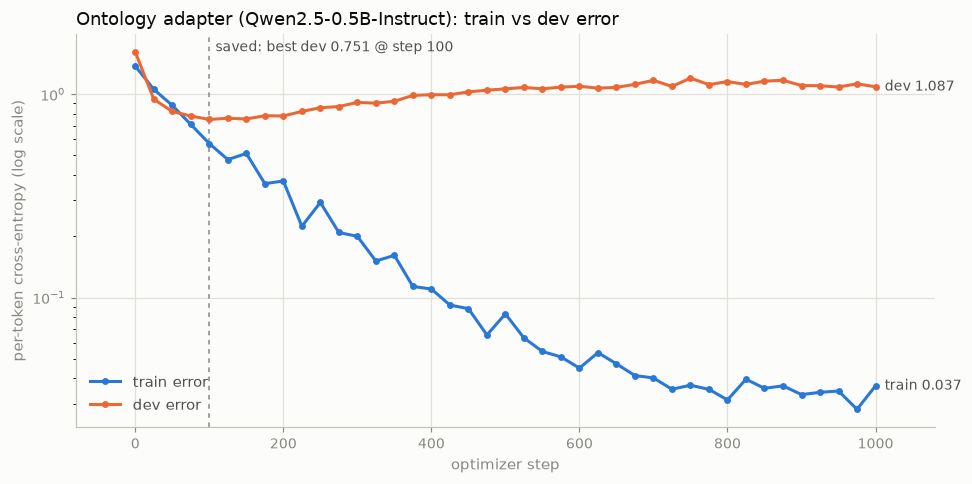

In [9]:
plot_history(ontology_result, "Ontology adapter (Qwen2.5-0.5B-Instruct): train vs dev error");

In [10]:
ontology_test = lora.evaluate(model, X_test_ontology, Y_test_ontology)
print(f"Test error (per-token cross-entropy): base model {ontology_base_test:.4f} -> LoRA {ontology_test:.4f}")

row = test_set.iloc[0]
generated = lora.generate(model, tokenizer, lora.instruct_prompt(row), max_new_tokens=400)
print("SECTION:", row["path"], "#", row["section"])
print("\nGENERATED:\n", generated[:1500])
print("\nGOLD:\n", json.dumps(json.loads(row["entities"]), ensure_ascii=False)[:1500])

del model
gc.collect(); torch.cuda.empty_cache()

Test error (per-token cross-entropy): base model 1.6331 -> LoRA 0.7835


SECTION: catalog-portfolio-api/latest/guide/troubleshooting/README.md # Troubleshooting > Common Error Categories > 🔧 Startup Issues

GENERATED:
  {"entities": [{"name": "catalog-portfolio-api", "type": "Service"}, {"name": "Startup issues", "type": "Error"}, {"name": "Port already in use", "type": "Error"}, {"name": "MySQL connection failed", "type": "Error"}, {"name": "FileNotFoundError", "type": "Error"}], "relationships": [{"source": "Startup issues", "relation": "related_to", "target": "Port already in use"}, {"source": "Startup issues", "relation": "related_to", "target": "MySQL connection failed"}, {"source": "Startup issues", "relation": "related_to", "target": "FileNotFoundError"}, {"source": "Port already in use", "relation": "related_to", "target": "Startup issues"}]}}

GOLD:
 {"entities": [{"name": "catalog-portfolio-api", "type": "Service"}, {"name": "Port Already in Use", "type": "Error"}, {"name": "Database Connection Failed", "type": "Error"}, {"name": "Missing Configur

### 4.6 Memory adapter: `Qwen2.5-Coder-0.5B-Instruct`
Same split, LoRA settings and stopping rule. The target is the raw section text (`X_*_memory`).

In [11]:
model = lora.load_lora_model(lora.MEMORY_MODEL)
memory_base_test = lora.evaluate(model, X_test_memory, Y_test_memory)

memory_result = lora.train_lora(
    model, X_train_memory, Y_train_memory, X_dev_memory, Y_dev_memory,
    save_path=MEMORY_LORA_PATH, **TRAIN_KW,
)
print(f"stopped by {memory_result.stop_reason} after {memory_result.steps_run} steps "
      f"in {memory_result.seconds / 60:.1f} min; saved best-dev weights (step {memory_result.best_step}) to {MEMORY_LORA_PATH}")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

step    0 | train 1.8725 | dev 2.5666


step   25 | train 1.7389 | dev 2.1874 | best dev 2.1874 @ 25


step   50 | train 1.6603 | dev 1.9904 | best dev 1.9904 @ 50


step   75 | train 1.3726 | dev 1.9185 | best dev 1.9185 @ 75


...

step  900 | train 0.0458 | dev 2.9810 | best dev 1.8692 @ 100


step  925 | train 0.0463 | dev 2.9700 | best dev 1.8692 @ 100


step  950 | train 0.0434 | dev 2.9562 | best dev 1.8692 @ 100


step  975 | train 0.0365 | dev 2.9990 | best dev 1.8692 @ 100


step 1000 | train 0.0373 | dev 3.0724 | best dev 1.8692 @ 100
stopped by max_steps after 1000 steps in 5.7 min; saved best-dev weights (step 100) to data/memory_lora.bin


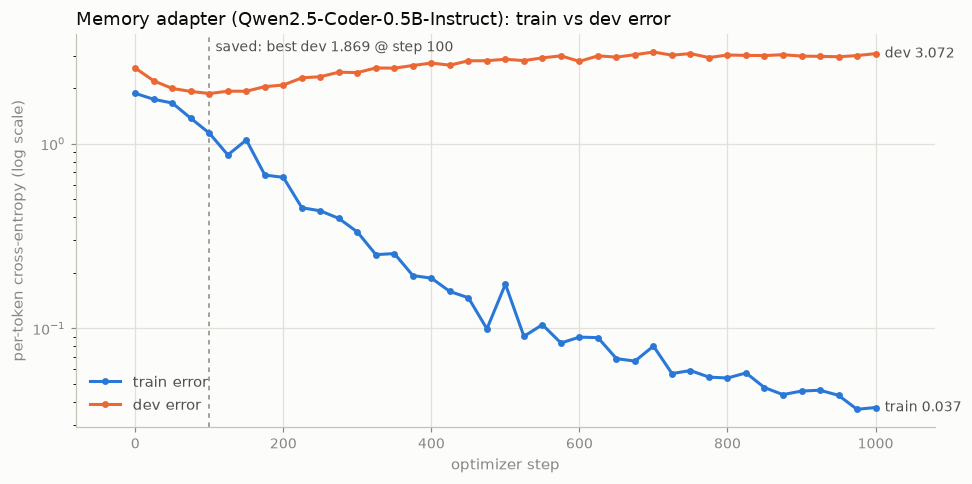

In [12]:
plot_history(memory_result, "Memory adapter (Qwen2.5-Coder-0.5B-Instruct): train vs dev error");

In [13]:
memory_test = lora.evaluate(model, X_test_memory, Y_test_memory)
print(f"Test error (per-token cross-entropy): base model {memory_base_test:.4f} -> LoRA {memory_test:.4f}")
del model
gc.collect(); torch.cuda.empty_cache()

pd.DataFrame(
    {
        "ontology (Qwen2.5-0.5B-Instruct)": {
            "steps run": ontology_result.steps_run, "stop reason": ontology_result.stop_reason,
            "saved step (best dev)": ontology_result.best_step, "best dev error": ontology_result.best_dev_loss,
            "test error, base": ontology_base_test, "test error, LoRA": ontology_test,
        },
        "memory (Qwen2.5-Coder-0.5B-Instruct)": {
            "steps run": memory_result.steps_run, "stop reason": memory_result.stop_reason,
            "saved step (best dev)": memory_result.best_step, "best dev error": memory_result.best_dev_loss,
            "test error, base": memory_base_test, "test error, LoRA": memory_test,
        },
    }
)

Test error (per-token cross-entropy): base model 2.2692 -> LoRA 1.7291


,ontology (Qwen2.5-0.5B-Instruct),memory (Qwen2.5-Coder-0.5B-Instruct)
steps run,1000,1000
stop reason,max_steps,max_steps
saved step (best dev),100,100
best dev error,0.7507278938503259,1.86920916577602947
"test error, base",1.63314154606295392,2.26923890618486723
"test error, LoRA",0.78347769925614963,1.72910779216568411


## 5. RAG experiments

| RAG | Generator | Retrieval |
|---|---|---|
| `memory_lora_only` | Qwen2.5-Coder-0.5B-Instruct + memory LoRA | none |
| `base_plus_retrieval` | Qwen2.5-Coder-0.5B-Instruct (no fine-tuning) | Chroma + ontology |
| `memory_lora_plus_retrieval` | Qwen2.5-Coder-0.5B-Instruct + memory LoRA | Chroma + ontology |

### 5.1 Questions
80 answerable questions with the section that answers each one (`source`), plus 20 that the documentation can't answer. Their expected answer is *"I don't have information about that topic"*.

In [14]:
questions = json.load(open(QUESTIONS_PATH))
qdf = pd.DataFrame(questions)
print(qdf["answerable"].value_counts().to_dict())
qdf.sample(5, random_state=0)[["prompt", "answer", "answerable"]]

{True: 80, False: 20}


,prompt,answer,answerable
26,What file is needed to run order-workflow-api tests against gh-proxy?,A private key file at src/main/resources/workflow-gh-proxy.key.,True
86,What machine learning model replaced Prophet in the forecasting project in 2025?,I don't have information about that topic,False
2,Which endpoint of vendor-stockkeeper-api handles the Feed Consumer?,POST /fp/inventory/operations/feed.,True
55,What does the marketplace forecasting project forecast?,"The demand of products in the marketplace, giving TGMV and TSI for 9 product categories plus the...",True
75,What is the maximum size of a configuration JSON in unified-transaction-configs?,"50kb, a limitation of KVS.",True


### 5.2 Sections to index
Rows with `For_training = 1` and `is_TO_DO = 0`: one copy per near-duplicate group, and no placeholders.

In [15]:
index_sections = pd.read_parquet(SECTIONS_PATH)
index_sections = index_sections[(index_sections["For_training"] == 1) & (index_sections["is_TO_DO"] == 0)].reset_index(drop=True)
print(f"{len(index_sections)} sections from {index_sections['path'].nunique()} files")

248 sections from 44 files


### 5.3 Ontology extraction with the trained adapter
Cached in `data/sections_extracted_entities.parquet`. Truncated JSON outputs are recovered entity by entity.

In [16]:
onto = rag.OntologyIndex.from_file(ONTOLOGY_PATH)
keys = [rag.section_key(r) for _, r in index_sections.iterrows()]
if REUSE_EXTRACTIONS and EXTRACTIONS_PATH.exists() and set(pd.read_parquet(EXTRACTIONS_PATH)["key"]) == set(keys):
    extractions = pd.read_parquet(EXTRACTIONS_PATH)
    print("loaded cached extractions")
else:
    onto_model = lora.load_lora_weights(lora.ONTOLOGY_MODEL, ONTOLOGY_LORA_PATH)
    start = time.perf_counter()
    extractions = rag.extract_section_entities(index_sections, onto_model, tokenizer, batch_size=8)
    print(f"extracted {len(extractions)} sections in {time.perf_counter() - start:.0f}s")
    extractions.to_parquet(EXTRACTIONS_PATH, index=False)
    del onto_model
    gc.collect(); torch.cuda.empty_cache()
print(f"parsed outputs: {extractions['parsed'].mean():.1%}")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

extracted 248 sections in 92s


parsed outputs: 100.0%


In [17]:
# Extractor vs Claude's annotations: entity-name precision / recall / F1 by split
split_of = {**{rag.section_key(r): "train" for _, r in training_set.iterrows()},
            **{rag.section_key(r): "test" for _, r in test_set.iterrows()},
            **{rag.section_key(r): "dev" for _, r in dev_set.iterrows()}}
gold_by_key = {rag.section_key(r): r["entities"] for _, r in df.iterrows()}
prf = pd.DataFrame(
    [(k, split_of[k], *rag.entity_prf(gold_by_key[k], e, onto)) for k, e in zip(extractions["key"], extractions["extracted"])],
    columns=["key", "split", "precision", "recall", "f1"],
)
prf.groupby("split")[["precision", "recall", "f1"]].mean()

,precision,recall,f1
split,,,
dev,0.63888888888888884,0.40355555555555556,0.47073762838468725
test,0.74266666666666670,0.56266666666666665,0.59296059496059494
train,0.78263644840598590,0.55022653267053789,0.61089466162303763


### 5.4 Vector database: bge-m3 embeddings in Chroma

In [18]:
embeddings = rag.load_embeddings()
docs = rag.build_documents(index_sections, extractions, onto)
store = rag.build_vector_store(docs, embeddings, CHROMA_DIR)
print(f"{store._collection.count()} documents in {CHROMA_DIR}")

answerable = [q for q in questions if q["answerable"]]
def hit_rate(retriever):
    return np.mean([q["source"] in retriever.retrieve(q["prompt"]).keys for q in answerable])

retriever = rag.OntologyRetriever(store, onto, k=K, fetch_k=FETCH_K, entity_boost=ENTITY_BOOST)
plain = rag.OntologyRetriever(store, onto, k=K, fetch_k=FETCH_K, entity_boost=0.0)
pd.Series({f"hit@{K}, bge-m3 only": hit_rate(plain), f"hit@{K}, bge-m3 + ontology boost": hit_rate(retriever)})

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

248 documents in data/chroma


hit@3, bge-m3 only                0.875
hit@3, bge-m3 + ontology boost    0.875
dtype: float64

### 5.5 The three RAGs
One Qwen2.5-Coder-0.5B-Instruct model is loaded with the memory adapter. `base_plus_retrieval` runs the same weights with the adapter switched off.

In [19]:
coder = lora.load_lora_weights(lora.MEMORY_MODEL, MEMORY_LORA_PATH)
rags = [
    rag.RAG("memory_lora_only", rag.Generator(coder, coder_tokenizer, use_adapter=True)),
    rag.RAG("base_plus_retrieval", rag.Generator(coder, coder_tokenizer, use_adapter=False), retriever),
    rag.RAG("memory_lora_plus_retrieval", rag.Generator(coder, coder_tokenizer, use_adapter=True), retriever),
]
q = answerable[5]
print("Q:", q["prompt"], "\nExpected:", q["answer"])
for r in rags:
    out = r.run(q["prompt"])
    print(f"- {r.name} ({out['seconds']}s): {out['answer']}")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Q: What are the database names of vendor-stockkeeper-api for test, stage and prod? 
Expected: inventtest for test, inventstg for stage and inventprd for prod, all on host proxysql.master.techzoneseginf.com port 6612.
- memory_lora_only (0.07667562200003886s): vendor-stockkeeper-api-test


- base_plus_retrieval (0.22681574699890916s): The database names for vendor-stockkeeper-api for test, stage, and prod are `inventtest`, `vendor-stockkeeper-api`, and `vendor-stockkeeper-api`.
- memory_lora_plus_retrieval (0.18385066100017866s): [Vendor-Stockkeeper-API] databases.md > Test: inventtest


### 5.6 Evaluation
For each question and RAG:
- `cosine_similarity`: bge-m3 cosine between the answer and the expected answer (not rounded)
- `seconds`: how long the RAG took to answer (retrieval + generation)

In [20]:
results = rag.evaluate_rags(rags, questions, embeddings)
results.to_parquet(RESULTS_PATH, index=False)

summary = results.groupby("rag", sort=False).agg(
    cosine_mean=("cosine_similarity", "mean"),
    cosine_median=("cosine_similarity", "median"),
    seconds_mean=("seconds", "mean"),
    seconds_median=("seconds", "median"),
    seconds_total=("seconds", "sum"),
)
summary

memory_lora_only: 100 answers in 25.1s


base_plus_retrieval: 100 answers in 20.5s


memory_lora_plus_retrieval: 100 answers in 25.6s


,cosine_mean,cosine_median,seconds_mean,seconds_median,seconds_total
rag,,,,,
memory_lora_only,0.58253844350794270,0.56450886867090755,0.25142287180991846,0.18901335099872085,25.14228718099184334
base_plus_retrieval,0.65370721296357592,0.71388492390537306,0.20500898851005331,0.15721940049843397,20.50089885100533138
memory_lora_plus_retrieval,0.66297367042751743,0.68250379081696866,0.25639794128004723,0.22518945399860968,25.63979412800472346


In [21]:
by_type = results.assign(question_type=np.where(results["answerable"], "answerable", "unanswerable")).pivot_table(
    index="rag", columns="question_type", values="cosine_similarity", aggfunc="mean", sort=False
)
by_type["refusal rate on unanswerable"] = results[~results["answerable"]].groupby("rag", sort=False)["refused"].mean()
by_type["false refusals on answerable"] = results[results["answerable"]].groupby("rag", sort=False)["refused"].mean()
by_type["source retrieved (answerable)"] = results[results["answerable"]].groupby("rag", sort=False)["source_retrieved"].mean()
by_type

question_type,answerable,unanswerable,refusal rate on unanswerable,false refusals on answerable,source retrieved (answerable)
rag,,,,,
memory_lora_only,0.59770911931614124,0.52185574027514881,0.25000000000000000,0.0125,NaN
base_plus_retrieval,0.72760641098045031,0.35811042089607781,0.00000000000000000,0.0000,0.875
memory_lora_plus_retrieval,0.68319380606602542,0.58209312787348533,0.34999999999999998,0.0125,0.875


In [22]:
# Per-question cosine similarity and seconds, side by side
results.pivot_table(index=["question_id", "prompt"], columns="rag", values=["cosine_similarity", "seconds"], sort=False).head(20)

cosine_similarity  \
rag                                                                                                                  memory_lora_only   
question_id prompt                                                                                                                      
0           What is vendor-stockkeeper-api responsible for?                                                       0.48274937687718844   
1           Which endpoint of vendor-stockkeeper-api handles the Restock Consumer?                                0.63964237667793511   
2           Which endpoint of vendor-stockkeeper-api handles the Feed Consumer?                                   0.67687683597408332   
3           What is the production base URL of vendor-stockkeeper-api on the TechZone Platform?                   0.78693699617473334   
4           What field does the restock-new request body carry inside msg?                                        0.43390929676426820   
5           What are the database names of vendor-stockkeeper-api for test, stage and prod?                       0.49066561222725130   
6           Which two inventory flows require verifying test items before executing actions?                      0.50674236619529289   
7           How do you identify that an item is a test item in the restock flow?                                  0.68469152903970876   
8           In the Feed flow, which table is queried with the operation id?                                       0.50017654407152945   
9           What should you do when the alert 'Stockkeeper-api - Error restocking item (negative quantity)' f...  0.50242059056155108   
10          Where should a ticket be raised to block a publication and prevent out-of-stock sales?                0.43492667298449905   
11          What is payment-promise-gateway?                                                                      0.60637289653841864   
12          Which Java version and framework does payment-promise-gateway use?                                    0.60439770917160374   
13          Which dependency injection library does payment-promise-gateway use?                                  0.49208504594016172   
14          Which endpoint creates a payment promise in payment-promise-gateway?                                  0.76460970615469603   
15          Which endpoint confirms a late fee forgiveness proposal?                                              0.84979959116411996   
16          What does GET /payment_promise/form return?                                                           0.70970400498792430   
17          Which header identifies the user in GET /payment_promise/active?                                      0.73217147408028294   
18          What environment variable must be set to run payment-promise-gateway locally?                         0.56699673673363971   
19          Which design pattern does PromiseCommand illustrate in payment-promise-gateway?                       0.66568353943755354   

                                                                                                                                       \
rag                                                                                                               base_plus_retrieval   
question_id prompt                                                                                                                      
0           What is vendor-stockkeeper-api responsible for?                                                       0.78469929454392096   
1           Which endpoint of vendor-stockkeeper-api handles the Restock Consumer?                                0.71895577695148105   
2           Which endpoint of vendor-stockkeeper-api handles the Feed Consumer?                                   0.61005883239393410   
3           What is the production base URL of vendor-stockkeeper-api on the TechZone Platform?                   0.78701689883835257   
4    